# Cuaderno 1 · Keras básico
## Clasificación binaria, clasificación multiclase y regresión

**Postgrado en Inteligencia Artificial para la Ingeniería Aeroespacial · Deep Learning con Keras**

En este cuaderno ponemos en práctica lo visto en las sesiones 2 y 3: construimos, entrenamos y evaluamos tres perceptrones multicapa, uno por cada tipo de problema.

| Parte | Problema | Ejemplo aeroespacial | Salida | Pérdida |
|---|---|---|---|---|
| 1 | Clasificación binaria | ¿Fallará el rodamiento? | 1 neurona · `sigmoid` | `binary_crossentropy` |
| 2 | Clasificación multiclase | Estado del turbofán (4 clases) | 4 neuronas · `softmax` | `sparse_categorical_crossentropy` |
| 3 | Regresión | Carrera de despegue | 1 neurona · lineal | `mse` |

Los tres siguen las mismas etapas: **datos → preparar → definir → compilar → entrenar → evaluar**.

> **Sobre los datos.** Para que el cuaderno funcione sin descargas, los conjuntos de datos se **generan de forma sintética** dentro del propio cuaderno, a partir de relaciones físicas sencillas más ruido. Son realistas en su forma, pero no son mediciones reales.

## 0 · Preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

keras.utils.set_random_seed(42)   # resultados reproducibles (numpy, Python y backend)
print("Keras", keras.__version__, "· backend:", keras.backend.backend())

Keras 3.15.1 · backend: tensorflow


In [2]:
AZUL, NARANJA, GRIS = "#0D6FCF", "#E8791E", "#6B6B6B"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def curvas(history, metrica=None, log=False):
    # Dibuja la pérdida (y opcionalmente una métrica) de entrenamiento y validación por época.
    h = history.history
    n = 2 if metrica else 1
    fig, axes = plt.subplots(1, n, figsize=(5.5 * n, 3.6))
    axes = np.atleast_1d(axes)
    for ax, clave in zip(axes, ["loss", metrica][:n]):
        ax.plot(h[clave], color=AZUL, label="entrenamiento")
        ax.plot(h["val_" + clave], color=NARANJA, label="validación")
        ax.set_xlabel("época"); ax.set_title(clave + (" (escala log)" if log else "")); ax.legend()
        if log:
            ax.set_yscale("log")
    plt.tight_layout(); plt.show()

---
## 1 · Clasificación binaria: ¿fallará el rodamiento?

Queremos predecir si un rodamiento de un motor **fallará en los próximos 50 ciclos de vuelo** a partir de cinco indicadores de su estado:

| Variable | Descripción |
|---|---|
| `vib_rms` | Valor eficaz de la vibración (g) |
| `curtosis` | Curtosis de la señal de vibración (impulsividad) |
| `temp_C` | Temperatura del rodamiento (°C) |
| `rpm` | Velocidad de giro (rpm) |
| `horas` | Horas desde el último mantenimiento |

La etiqueta `fallo` vale 1 si falla y 0 si no.

### 1.1 · Datos

In [3]:
rng = np.random.default_rng(0)
n = 4000

horas    = rng.uniform(0, 3000, n)
desgaste = horas / 3000 + rng.normal(0, 0.15, n)          # estado oculto de degradación
rpm      = rng.normal(12000, 800, n)
vib_rms  = 0.4 + 1.2 * desgaste**2 + 0.00004 * (rpm - 12000) + rng.normal(0, 0.12, n)
curtosis = 3.0 + 2.5 * np.clip(desgaste - 0.5, 0, None) + rng.normal(0, 0.4, n)
temp_C   = 70 + 25 * desgaste + 0.002 * (rpm - 12000) + rng.normal(0, 4, n)

# Probabilidad de fallo: no lineal en el desgaste y la impulsividad
logit = -6 + 5.5 * desgaste**2 + 0.9 * (curtosis - 3) + 0.04 * (temp_C - 85)
fallo = (rng.uniform(size=n) < 1 / (1 + np.exp(-logit))).astype(int)

df_rod = pd.DataFrame({"vib_rms": vib_rms, "curtosis": curtosis, "temp_C": temp_C,
                       "rpm": rpm, "horas": horas, "fallo": fallo})
df_rod.head()

,vib_rms,curtosis,temp_C,rpm,horas,fallo
0,0.461754,2.738397,75.007924,11645.437408,1910.885062,0
1,0.553612,2.911050,83.287529,13175.491763,809.360141,0
2,0.596394,2.862601,75.271264,13911.789559,122.920572,0
3,0.475584,2.874783,54.610280,11352.369915,49.582907,0
4,1.001056,3.646275,86.232778,12985.175805,2439.810718,0


In [4]:
print(df_rod["fallo"].value_counts(normalize=True).rename("proporción"))
df_rod.describe().round(2)

fallo
0    0.87375
1    0.12625
Name: proporción, dtype: float64


,vib_rms,curtosis,temp_C,rpm,horas,fallo
count,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00
mean,0.83,3.34,82.47,12015.22,1489.86,0.13
std,0.43,0.61,9.29,796.65,864.80,0.33
min,-0.08,1.78,51.45,9273.77,0.57,0.00
25%,0.50,2.91,75.72,11483.55,741.98,0.00
50%,0.73,3.29,82.62,12021.75,1475.80,0.00
75%,1.10,3.72,89.24,12567.55,2249.96,0.00
max,2.97,5.77,109.77,15156.44,2998.70,1.00


Las clases están algo desbalanceadas (hay más rodamientos sanos que con fallo): lo tendremos en cuenta al elegir las métricas. Fíjate también en las **escalas tan distintas** de las variables (las `rpm` rondan 12.000 y la `curtosis` está en torno a 3): por eso hay que normalizar.

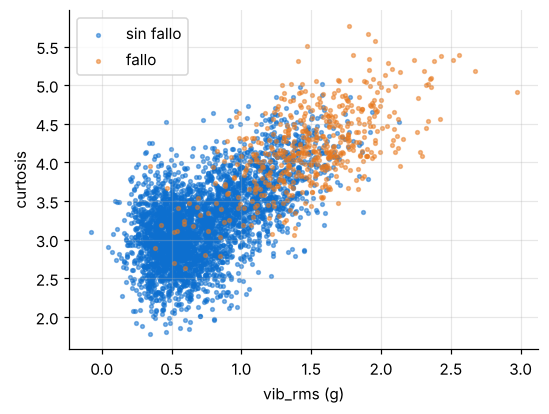

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for c, col, lab in [(0, AZUL, "sin fallo"), (1, NARANJA, "fallo")]:
    d = df_rod[df_rod.fallo == c]
    ax.scatter(d.vib_rms, d.curtosis, s=6, alpha=0.5, color=col, label=lab)
ax.set_xlabel("vib_rms (g)"); ax.set_ylabel("curtosis"); ax.legend(); plt.show()

### 1.2 · Preparar: dividir en entrenamiento, validación y prueba

Usamos 70 % / 15 % / 15 %. `stratify` mantiene la misma proporción de fallos en los tres conjuntos.

In [6]:
X = df_rod.drop(columns="fallo").to_numpy(dtype="float32")
y = df_rod["fallo"].to_numpy()

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=0)
print("entrenamiento:", X_train.shape, " validación:", X_val.shape, " prueba:", X_test.shape)

entrenamiento: (2800, 5)  validación: (600, 5)  prueba: (600, 5)


La capa `Normalization` calcula la media y la desviación típica de cada variable con `adapt()`. **Solo** se adapta con el conjunto de entrenamiento, para no filtrar información de validación ni de prueba. Al ir dentro del modelo, la normalización viaja con él cuando lo guardemos o exportemos.

In [7]:
norm_rod = layers.Normalization()
norm_rod.adapt(X_train)
print("medias:", np.round(norm_rod.mean.numpy().ravel(), 2).tolist())

medias: [0.8299999833106995, 3.3499999046325684, 82.52999877929688, 12018.1796875, 1498.3699951171875]


### 1.3 · Definir el modelo

Para clasificación binaria, la última capa tiene **una neurona con activación sigmoide**: su salida es la probabilidad de fallo.

In [8]:
modelo_bin = keras.Sequential([
    keras.Input(shape=(5,)),
    norm_rod,
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="rodamiento")
modelo_bin.summary()

Model: "rodamiento"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 5)              │            11 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252 (1012.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 11 (48.00 B)

**Comprueba los parámetros** con la fórmula de la sesión 2, *entradas × neuronas + neuronas*:

- `Dense(16)`: 5·16 + 16 = **96**
- `Dense(8)`: 16·8 + 8 = **136**
- `Dense(1)`: 8·1 + 1 = **9**

La capa `Normalization` añade 11 parámetros **no entrenables** (5 medias, 5 varianzas y un contador).

### 1.4 · Compilar y entrenar

Además de la *accuracy*, pedimos **precisión** y **recall** de la clase «fallo», más informativas cuando hay desbalanceo.

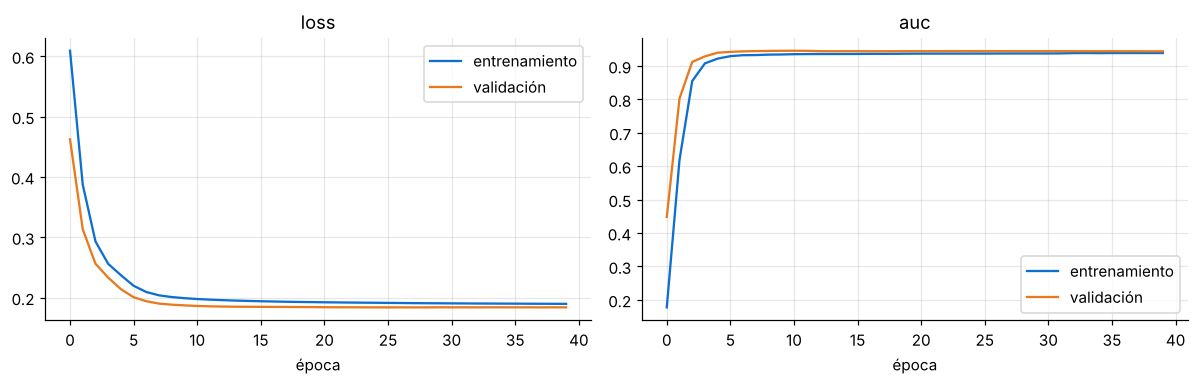

In [9]:
modelo_bin.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")],
)

hist_bin = modelo_bin.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=40, batch_size=32, verbose=0)
curvas(hist_bin, "auc")

### 1.5 · Evaluar en el conjunto de prueba

`evaluate()` devuelve la pérdida y las métricas. `predict()` devuelve **probabilidades**; para decidir aplicamos un umbral.

In [10]:
resultado = modelo_bin.evaluate(X_test, y_test, verbose=0, return_dict=True)
{k: round(v, 3) for k, v in resultado.items()}

{'accuracy': 0.918,
 'auc': 0.931,
 'loss': 0.199,
 'precision': 0.755,
 'recall': 0.526}

Primeras probabilidades: [0.023 0.001 0.011 0.024 0.477]


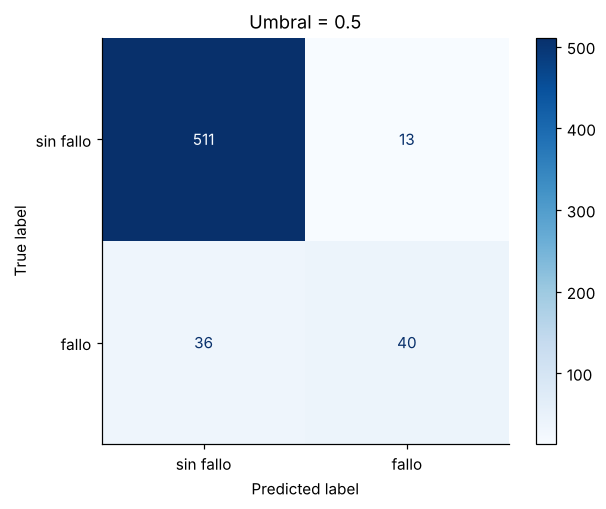

              precision    recall  f1-score   support

   sin fallo      0.934     0.975     0.954       524
       fallo      0.755     0.526     0.620        76

    accuracy                          0.918       600
   macro avg      0.844     0.751     0.787       600
weighted avg      0.911     0.918     0.912       600



In [11]:
p_test = modelo_bin.predict(X_test, verbose=0).ravel()   # P(fallo) para cada rodamiento
print("Primeras probabilidades:", p_test[:5].round(3))

umbral = 0.5
y_pred = (p_test >= umbral).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["sin fallo", "fallo"]).plot(cmap="Blues")
plt.grid(False); plt.title(f"Umbral = {umbral}"); plt.show()
print(classification_report(y_test, y_pred, target_names=["sin fallo", "fallo"], digits=3))

### 1.6 · El umbral es una decisión de ingeniería

En mantenimiento, **no detectar un fallo** (falso negativo) suele ser mucho más caro que una **falsa alarma**. Bajar el umbral detecta más fallos a cambio de más falsas alarmas.

In [12]:
for u in [0.5, 0.3, 0.15]:
    yp = (p_test >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    print(f"umbral {u:>4}:  fallos detectados {tp:3d}/{tp + fn}   no detectados {fn:3d}   falsas alarmas {fp:3d}")

umbral  0.5:  fallos detectados  40/76   no detectados  36   falsas alarmas  13
umbral  0.3:  fallos detectados  52/76   no detectados  24   falsas alarmas  37
umbral 0.15:  fallos detectados  64/76   no detectados  12   falsas alarmas  62


> **Ejercicios (parte 1)**
> 1. Quita la capa `Normalization` y vuelve a entrenar. ¿Qué pasa con las curvas de aprendizaje?
> 2. Prueba una red sin capas ocultas (solo `Dense(1, activation="sigmoid")`): es una **regresión logística**. ¿Cuánto empeora?
> 3. Elige un umbral que garantice detectar al menos el 95 % de los fallos de prueba. ¿Cuántas falsas alarmas cuesta?

---
## 2 · Clasificación multiclase: estado del turbofán

Retomamos el ejercicio de la sesión 2: clasificar el estado de un motor en **4 clases** a partir de **14 sensores**.

| Clase | Estado |
|---|---|
| 0 | Normal |
| 1 | Degradación del compresor |
| 2 | Degradación de la turbina |
| 3 | Fallo de sensor |

Los nombres de los sensores imitan los del conjunto C-MAPSS de la NASA (temperaturas T, presiones P, velocidades N...).

### 2.1 · Datos

In [13]:
rng = np.random.default_rng(1)
sensores = ["T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc", "Ps30", "phi", "NRf", "BPR", "W31"]
media    = np.array([518.7, 642.5, 1590, 1405, 14.6, 21.6, 553.5, 2388, 9065, 47.5, 521.6, 2388, 8.44, 38.9])
escala   = np.array([0.01, 0.5, 6, 9, 0.01, 0.01, 0.9, 0.07, 22, 0.27, 0.74, 0.07, 0.04, 0.18])
clases   = ["Normal", "Compresor", "Turbina", "Sensor"]

def generar_motor(n_por_clase=1500):
    X, y = [], []
    for c in range(4):
        Z = rng.normal(0, 1, (n_por_clase, 14))             # variación normal de cada sensor
        if c == 1:   # compresor: sube T24/T30, baja P30 y crece Ps30
            Z[:, [1, 2]] += 1.6; Z[:, 6] -= 1.4; Z[:, 9] += 1.2
        if c == 2:   # turbina: sube T50 (EGT) y cae la relación de presiones
            Z[:, 3] += 2.0; Z[:, 6] -= 0.8; Z[:, 13] -= 1.3
        if c == 3:   # sensor: una lectura con deriva grande en un sensor al azar
            idx = rng.integers(0, 14, n_por_clase)
            Z[np.arange(n_por_clase), idx] += rng.choice([-1, 1], n_por_clase) * rng.uniform(4, 7, n_por_clase)
        X.append(media + Z * escala); y.append(np.full(n_por_clase, c))
    return np.vstack(X).astype("float32"), np.concatenate(y)

X, y = generar_motor()
df_mot = pd.DataFrame(X, columns=sensores); df_mot["estado"] = y
df_mot.groupby("estado")[["T24", "T30", "T50", "P30", "Ps30"]].mean().rename(index=dict(enumerate(clases))).round(2)

,T24,T30,T50,P30,Ps30
estado,,,,,
Normal,642.500000,1589.819946,1404.540039,553.489990,47.509998
Compresor,643.289978,1599.540039,1404.699951,552.219971,47.820000
Turbina,642.500000,1590.069946,1422.849976,552.750000,47.500000
Sensor,642.500000,1590.089966,1405.349976,553.530029,47.520000


### 2.2 · Preparar

In [14]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=0)

norm_mot = layers.Normalization()
norm_mot.adapt(X_train)
print(X_train.shape, X_val.shape, X_test.shape)

(4199, 14) (901, 14) (900, 14)


### 2.3 · Definir: la red 14 → 32 → 16 → 4 del ejercicio de la sesión 2

La salida tiene **4 neuronas con softmax**: devuelve una probabilidad por clase, y las cuatro suman 1.

In [15]:
modelo_mc = keras.Sequential([
    keras.Input(shape=(14,)),
    norm_mot,
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(4, activation="softmax"),
], name="turbofan")
modelo_mc.summary()

Model: "turbofan"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 14)             │            29 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,105 (4.32 KB)

 Trainable params: 1,076 (4.20 KB)

 Non-trainable params: 29 (120.00 B)

Los parámetros entrenables son **480 + 528 + 68 = 1.076**, como calculamos en clase. La normalización añade 14 + 14 + 1 = 29 no entrenables.

Comprobemos también las formas de los pesos. Recuerda que **Keras guarda el kernel traspuesto**: `(entradas, neuronas)`.

In [16]:
for capa in modelo_mc.layers[1:]:
    W, b = capa.get_weights()
    print(f"{capa.name:8s}  kernel {str(W.shape):9s}  bias {b.shape}")

dense_3   kernel (14, 32)   bias (32,)
dense_4   kernel (32, 16)   bias (16,)
dense_5   kernel (16, 4)    bias (4,)


### 2.4 · Compilar y entrenar

Las etiquetas son **enteros** (0, 1, 2, 3), así que usamos `sparse_categorical_crossentropy`.

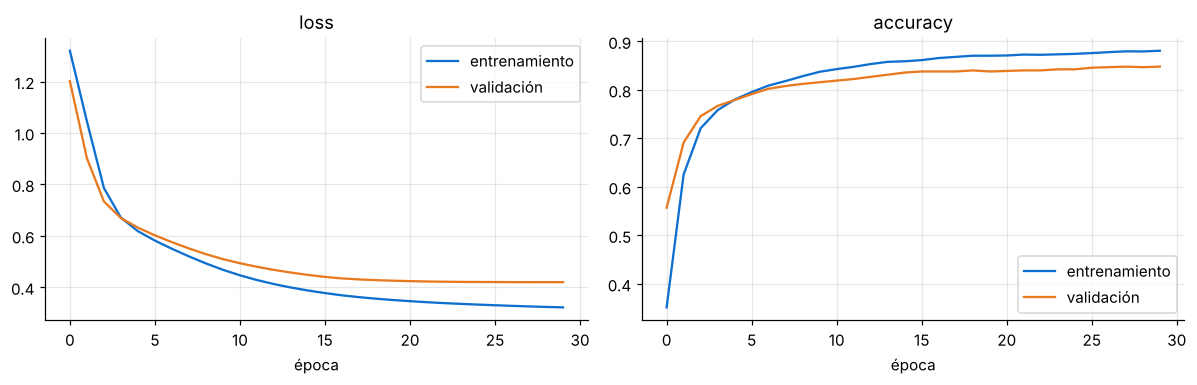

In [17]:
modelo_mc.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_mc = modelo_mc.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=30, batch_size=64, verbose=0)
curvas(hist_mc, "accuracy")

### 2.5 · Evaluar y predecir

Prueba: {'accuracy': 0.833, 'loss': 0.43}


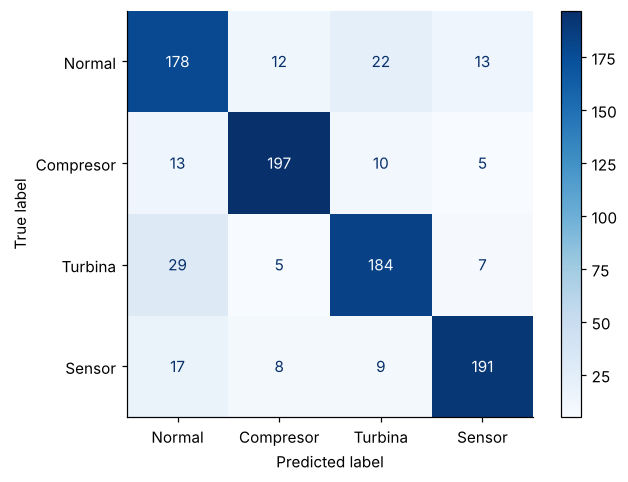

In [18]:
print("Prueba:", {k: round(v, 3) for k, v in modelo_mc.evaluate(X_test, y_test, verbose=0, return_dict=True).items()})

P = modelo_mc.predict(X_test, verbose=0)        # forma (n, 4): una probabilidad por clase
y_pred = P.argmax(axis=1)                         # clase más probable
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=clases).plot(cmap="Blues")
plt.grid(False); plt.show()

In [19]:
i = 0
print("Probabilidades del primer motor de prueba:")
for c, p in zip(clases, P[i]):
    print(f"  {c:10s} {p:6.3f}  " + "█" * int(40 * p))
print("Suma:", P[i].sum().round(4), "· predicción:", clases[y_pred[i]], "· real:", clases[y_test[i]])

Probabilidades del primer motor de prueba:
  Normal      0.240  █████████
  Compresor   0.068  ██
  Turbina     0.684  ███████████████████████████
  Sensor      0.008  
Suma: 1.0 · predicción: Turbina · real: Sensor


### 2.6 · Alternativa: etiquetas *one-hot*

Si las etiquetas vienen como vectores *one-hot*, la pérdida es `categorical_crossentropy`. Matemáticamente es la misma; solo cambia el formato.

In [20]:
y_train_oh = keras.utils.to_categorical(y_train, num_classes=4)
print(y_train[:3], "→\n", y_train_oh[:3])
# modelo.compile(loss="categorical_crossentropy", ...)  y  fit(X_train, y_train_oh, ...)

[1 3 2] →
 [[0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]


> **Ejercicios (parte 2)**
> 1. ¿Qué clases se confunden más entre sí? Mira la matriz de confusión y relaciona la respuesta con cómo se generaron los datos.
> 2. Cambia la última capa a `Dense(1, activation="softmax")` y entrena. ¿Qué ocurre y por qué? (Pista: diapositiva «¿Qué falla aquí?» de la sesión 2.)
> 3. Duplica las neuronas de las capas ocultas. ¿Cuántos parámetros tiene ahora la red? Compruébalo con `summary()`.

---
## 3 · Regresión: carrera de despegue

Queremos estimar la **distancia de carrera en el despegue** de un avión de pasillo único a partir de:

| Variable | Descripción |
|---|---|
| `masa_t` | Masa al despegue (t) |
| `empuje_kN` | Empuje total disponible (kN) |
| `altitud_m` | Elevación del aeropuerto (m) |
| `temp_C` | Temperatura exterior (°C) |
| `CLmax` | Coeficiente de sustentación máximo (configuración de flaps) |

Generamos los datos con la aproximación clásica de la carrera en tierra,

$$ s \approx \frac{1{,}44\, W^2}{g\, \rho\, S\, C_{L,\max}\, T}, $$

con $W = m g$, superficie alar $S = 122{,}6\ \text{m}^2$, y la densidad $\rho$ obtenida de la altitud y la temperatura con la atmósfera estándar. Añadimos un 4 % de ruido. **La red no conoce esta fórmula**: tiene que aprenderla a partir de los ejemplos.

### 3.1 · Datos

In [21]:
rng = np.random.default_rng(2)
n = 5000
g, S, R = 9.81, 122.6, 287.05

masa_t    = rng.uniform(50, 79, n)
empuje_kN = rng.uniform(190, 240, n)
altitud_m = rng.uniform(0, 2500, n)
temp_C    = rng.uniform(-10, 45, n)
CLmax     = rng.choice([2.0, 2.3, 2.6], n)

def densidad(alt, tC):
    p = 101325 * (1 - 2.25577e-5 * alt) ** 5.25588      # presión ISA a esa altitud
    return p / (R * (tC + 273.15))                       # densidad con la temperatura real

def carrera(m_t, T_kN, alt, tC, cl):
    W = m_t * 1000 * g
    return 1.44 * W**2 / (g * densidad(alt, tC) * S * cl * T_kN * 1000)

s_m = carrera(masa_t, empuje_kN, altitud_m, temp_C, CLmax) * rng.normal(1, 0.04, n)

df_to = pd.DataFrame({"masa_t": masa_t, "empuje_kN": empuje_kN, "altitud_m": altitud_m,
                      "temp_C": temp_C, "CLmax": CLmax, "carrera_m": s_m})
df_to.describe().round(1)

,masa_t,empuje_kN,altitud_m,temp_C,CLmax,carrera_m
count,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0
mean,64.6,214.9,1250.7,17.5,2.3,964.9
std,8.4,14.6,724.2,15.8,0.2,301.8
min,50.0,190.0,0.4,-10.0,2.0,328.5
25%,57.0,202.6,634.0,3.9,2.0,724.2
50%,64.4,214.9,1251.0,17.6,2.3,932.4
75%,72.0,227.7,1875.3,31.1,2.6,1165.6
max,79.0,240.0,2499.5,45.0,2.6,2151.6


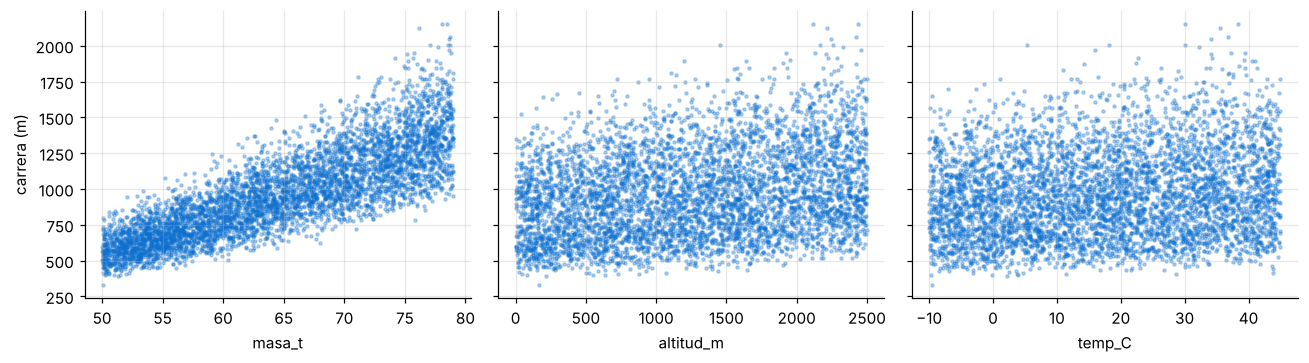

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, col in zip(axes, ["masa_t", "altitud_m", "temp_C"]):
    ax.scatter(df_to[col], df_to["carrera_m"], s=4, alpha=0.3, color=AZUL)
    ax.set_xlabel(col)
axes[0].set_ylabel("carrera (m)"); plt.tight_layout(); plt.show()

### 3.2 · Preparar

Además de normalizar las entradas, **expresamos la salida en kilómetros** para que tenga un orden de magnitud cercano a 1. Las pérdidas con valores del orden de miles (o millones, al elevar al cuadrado) entrenan peor.

In [23]:
X = df_to.drop(columns="carrera_m").to_numpy(dtype="float32")
y = (df_to["carrera_m"] / 1000).to_numpy(dtype="float32")   # en km

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, random_state=0)

norm_to = layers.Normalization()
norm_to.adapt(X_train)

### 3.3 · Definir

En regresión la última capa tiene **una neurona sin activación** (lineal), para que la salida pueda tomar cualquier valor.

In [24]:
modelo_reg = keras.Sequential([
    keras.Input(shape=(5,)),
    norm_to,
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),                       # salida lineal
], name="despegue")
modelo_reg.summary()

Model: "despegue"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_2 (Normalization) │ (None, 5)              │            11 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,508 (9.80 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 11 (48.00 B)

### 3.4 · Compilar y entrenar

Pérdida **MSE** (error cuadrático medio) y métrica **MAE** (error absoluto medio), más fácil de interpretar: está en km.

Añadimos dos *callbacks* (funciones que Keras llama al final de cada época):

- `ReduceLROnPlateau`: divide la tasa de aprendizaje por 2 cuando la validación se estanca (diapositiva «tasa de aprendizaje variable», sesión 3).
- `EarlyStopping`: para cuando la validación deja de mejorar y recupera los mejores pesos, así no hay que adivinar el número de épocas (lo veremos en detalle en la sesión 4).

Épocas entrenadas: 258


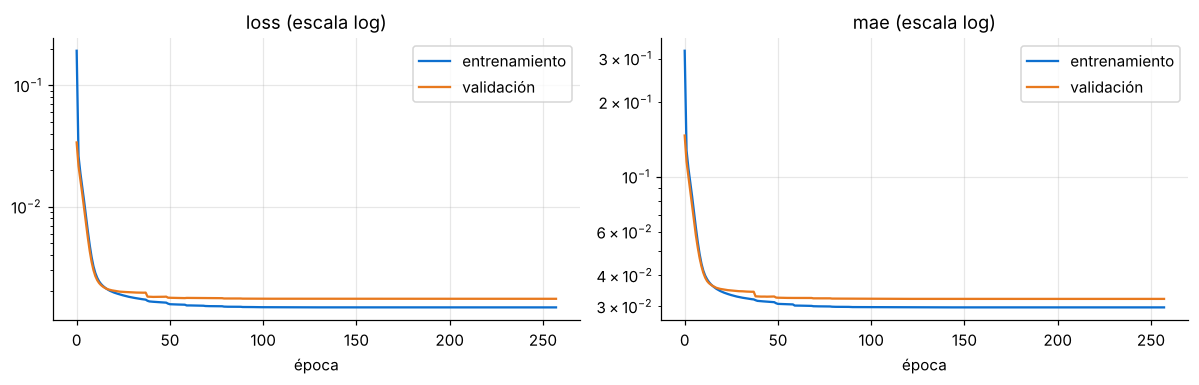

In [25]:
modelo_reg.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])

callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, restore_best_weights=True),
]
hist_reg = modelo_reg.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=600, batch_size=64, callbacks=callbacks, verbose=0)
print("Épocas entrenadas:", len(hist_reg.history["loss"]))
curvas(hist_reg, "mae", log=True)

### 3.5 · Evaluar: ¿es bueno este error?

Un error sin referencia no dice mucho. Lo comparamos con dos **líneas base**:

- predecir siempre la media del entrenamiento;
- una regresión lineal (sin capas ocultas).

In [26]:
from sklearn.linear_model import LinearRegression

pred_red   = modelo_reg.predict(X_test, verbose=0).ravel()
pred_media = np.full_like(y_test, y_train.mean())
pred_lin   = LinearRegression().fit(X_train, y_train).predict(X_test)

for nombre, p in [("siempre la media", pred_media), ("regresión lineal", pred_lin), ("red neuronal", pred_red)]:
    mae_m = np.mean(np.abs(p - y_test)) * 1000
    print(f"{nombre:18s} MAE = {mae_m:6.1f} m")
# Con un ruido multiplicativo del 4 %, ni el modelo perfecto bajaría de ≈ 0,8 · 4 % · carrera media
print(f"\nLímite por el ruido de los datos: ≈ {0.8 * 0.04 * y_test.mean() * 1000:.0f} m")

siempre la media   MAE =  244.3 m
regresión lineal   MAE =   46.1 m
red neuronal       MAE =   34.7 m

Límite por el ruido de los datos: ≈ 31 m


La red queda cerca del **límite que impone el ruido** de los datos: no se puede bajar mucho más. La regresión lineal se queda por detrás porque la relación real es no lineal (la masa entra al cuadrado; el empuje y la densidad, dividiendo). Con estos rangos la relación es suave y casi lineal, por eso la diferencia no es enorme: prueba a ampliar los rangos (ejercicio 4).

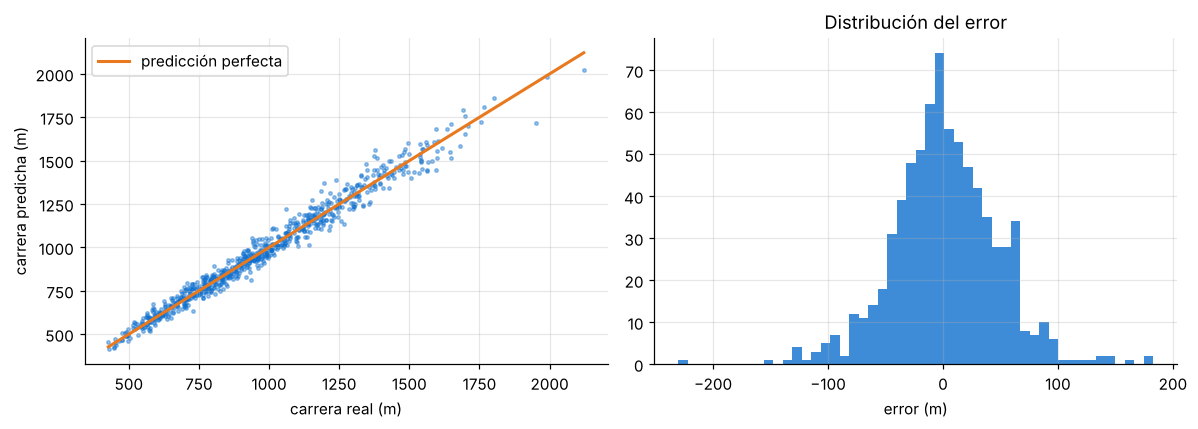

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test * 1000, pred_red * 1000, s=5, alpha=0.4, color=AZUL)
lim = [y_test.min() * 1000, y_test.max() * 1000]
axes[0].plot(lim, lim, color=NARANJA, lw=2, label="predicción perfecta")
axes[0].set_xlabel("carrera real (m)"); axes[0].set_ylabel("carrera predicha (m)"); axes[0].legend()
axes[1].hist((pred_red - y_test) * 1000, bins=50, color=AZUL, alpha=0.8)
axes[1].set_xlabel("error (m)"); axes[1].set_title("Distribución del error")
plt.tight_layout(); plt.show()

### 3.6 · Usar el modelo: «hot and high»

Comparamos el mismo avión despegando a nivel del mar en un día estándar y en un aeropuerto alto (≈ 600 m, como Madrid-Barajas) en un día caluroso.

In [28]:
casos = np.array([
    # masa_t, empuje_kN, altitud_m, temp_C, CLmax
    [70, 220,   0, 15, 2.3],
    [70, 220, 610, 38, 2.3],
], dtype="float32")

pred = modelo_reg.predict(casos, verbose=0).ravel() * 1000
fisica = carrera(*casos.T)
for nombre, p, f in zip(["Nivel del mar, 15 °C", "610 m, 38 °C"], pred, fisica):
    print(f"{nombre:22s} red: {p:6.0f} m   fórmula: {f:6.0f} m")

Nivel del mar, 15 °C   red:    953 m   fórmula:    911 m
610 m, 38 °C           red:   1034 m   fórmula:   1058 m


Fíjate en que una predicción concreta puede desviarse más que el MAE medio, sobre todo **cerca de los bordes del rango de entrenamiento** (0 m de altitud es justo el límite inferior). El MAE es un promedio, no una garantía caso a caso.

> **Ejercicios (parte 3)**
> 1. Entrena con la salida en metros (sin dividir por 1000). ¿Qué observas en la pérdida y en el tiempo de convergencia?
> 2. Sustituye `loss="mse"` por `loss="mae"`. ¿Cambia el resultado?
> 3. Prueba el modelo fuera del rango de entrenamiento (por ejemplo, un aeropuerto a 4.000 m). Compara con la fórmula: ¿se puede confiar en una red fuera de los datos que ha visto?
> 4. Amplía el rango de masas (por ejemplo de 40 a 90 t) y de altitudes (0 a 4.000 m). ¿Aumenta la ventaja de la red frente a la regresión lineal?

---
## 4 · Resumen y guardar los modelos

| | Binaria | Multiclase | Regresión |
|---|---|---|---|
| Última capa | `Dense(1, activation="sigmoid")` | `Dense(K, activation="softmax")` | `Dense(1)` |
| Pérdida | `binary_crossentropy` | `sparse_categorical_crossentropy` | `mse` (o `mae`) |
| `predict()` devuelve | P(clase 1) | K probabilidades | el valor |
| Decisión | `p >= umbral` | `argmax` | usar el valor |
| Métricas útiles | precisión, recall, AUC | accuracy, matriz de confusión | MAE, RMSE |

Las capas ocultas son iguales en los tres casos (`Dense` + `relu`): lo que cambia es la **salida** y la **pérdida**.

Guardamos los modelos en el formato nativo `.keras` (arquitectura, pesos y estado del optimizador). La exportación a ONNX la veremos en un cuaderno posterior.

In [29]:
modelo_bin.save("rodamiento.keras")
modelo_mc.save("turbofan.keras")
modelo_reg.save("despegue.keras")

recargado = keras.models.load_model("despegue.keras")
print("Misma predicción tras recargar:",
      np.allclose(recargado.predict(casos, verbose=0), modelo_reg.predict(casos, verbose=0)))

Misma predicción tras recargar: True
